In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

m,cm=1,0.01
class Detector():
    def __init__(self, R=2*m,N=40,r=10*cm, prob=0.5):
        self.R=R
        self.N=N
        self.r=r
        self.prob=prob
        self.PMTArray=self.uniform_distribution()
    def uniform_distribution(self):
        i = np.arange(self.N)
        golden_ratio = (1 + np.sqrt(5)) / 2
        cosTheta = 1 - 2 * (i + 0.5) / self.N
        sinTheta = np.sqrt(1 - cosTheta*cosTheta)
        phi = 2 * np.pi * i / golden_ratio
        return self.R * np.array([sinTheta * np.cos(phi),sinTheta * np.sin(phi),cosTheta])
        
    def IsInPMT(self,origin:np.ndarray,PhotonArray:np.ndarray):
        cosMax=np.cos(self.r/self.R)
        cosCheck=(origin[:, None]+PhotonArray).T@ self.PMTArray/ (self.R ** 2)
        return np.any(cosCheck>cosMax, axis=1)
        
    def ElectronYield(self, NDetected:float):
        return np.random.poisson(self.prob * NDetected)

class Source():
    def __init__(self, E:float,origin:np.ndarray,Y=1e4,L=8):
        self.Y=Y
        self.L=L
        self.N=np.random.poisson(E*Y) 
        self.origin=origin
    def photon_generator(self, bunch=100):
        left = self.N
        while left > 0:
            n = min(bunch, left)
            phi = np.random.uniform(0, 2 * np.pi, n)
            cosTheta = np.random.uniform(-1, 1, n)
            sinTheta = np.sqrt(1 - cosTheta * cosTheta)
            yield np.array([sinTheta * np.cos(phi),sinTheta * np.sin(phi),cosTheta]) 
            left -= n
    def distance_traversed(self,PhotonArray:np.ndarray,R:float):
        t=-self.origin@PhotonArray+np.sqrt(R**2-np.sum(self.origin**2)+(self.origin@PhotonArray)*(self.origin@PhotonArray))
        return t
    def attenuation(self, PhotonArray, R):
        t = self.distance_traversed(PhotonArray, R)
        gen_dist = -self.L*np.log(np.random.uniform(0, 1, len(t))) 
        return t<gen_dist

D1=Detector()

EventCount = 500
z_list = [0.0, 0.5, 1.0, 1.5]

def Event(EventCount:int, z, E=1,attenuate=True):
    origin = np.array([0.0, 0.0, z])
    N_e = np.empty(EventCount)
    for i in range(EventCount):
        S1=Source(E,origin)
        registered = 0
        for bunch in S1.photon_generator():
            t = S1.distance_traversed(bunch, D1.R)
            regs = bunch * t
            if attenuate:
                alive = S1.attenuation(bunch, D1.R)
                regs = regs[:, alive]
            registered += np.sum(D1.IsInPMT(origin, regs))
        N_e[i]=(D1.ElectronYield(registered))
    return np.array(N_e)   
sns.set_palette("Set2")
def plotter():
    for z in z_list:
        w_a = Event(EventCount,z, attenuate=True)
        n_a = Event(EventCount,z, attenuate=False)
        sns.histplot(n_a, bins=30,stat='density', kde=False, edgecolor='black', alpha=0.5, label="без затухания")
        sns.histplot(w_a, bins=30,stat='density', kde=False, edgecolor='black', alpha=0.5, label="L = 8 м")
        print(f'среднее с затуханием = {w_a.mean()}| без затухания = {n_a.mean()}')
        print(f'std с затуханием = {w_a.std(ddof=1):.3f}| без затухания = {n_a.std(ddof=1):.3f}')
        plt.title(f"z = {z} м")
        plt.legend()
        plt.xlabel("Number of electrons")
        plt.ylabel("Count")
        plt.show()

среднее с затуханием = 97.302| без затухания = 123.804
std с затуханием = 11.876| без затухания = 14.317


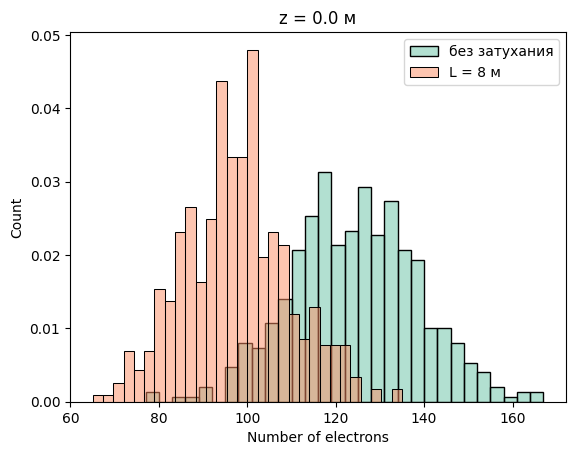

среднее с затуханием = 98.35| без затухания = 124.898
std с затуханием = 11.917| без затухания = 14.129


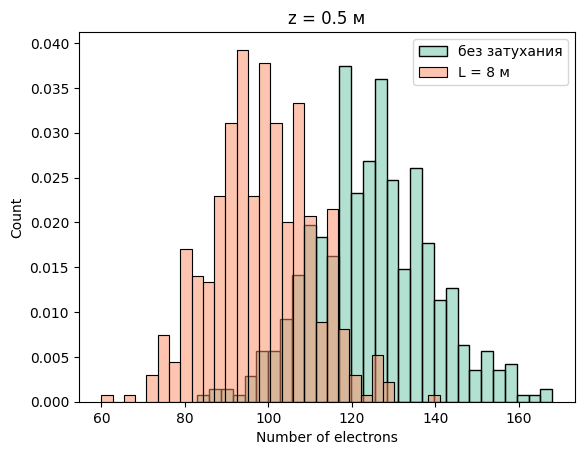

среднее с затуханием = 99.286| без затухания = 123.266
std с затуханием = 11.122| без затухания = 13.308


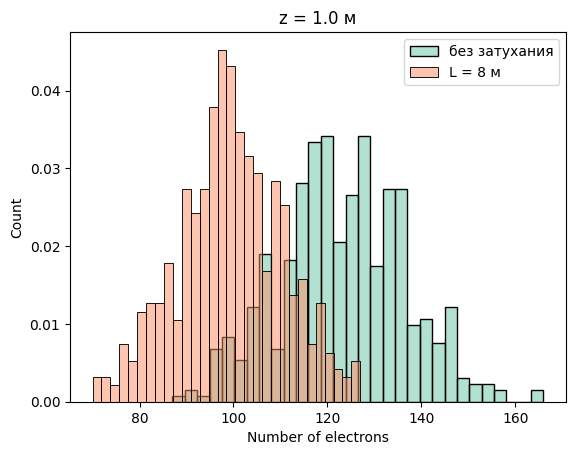

среднее с затуханием = 100.514| без затухания = 122.174
std с затуханием = 12.406| без затухания = 13.900


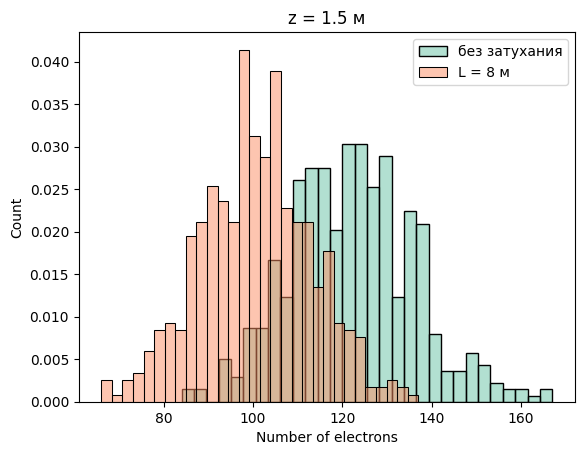

In [17]:
plotter()